## Transfer Learning Lab: Cats vs. Dogs

### We reuse ResNet50 features and only train a small classifier on top.



#### Goal: Build a cats‑vs‑dogs classifier using a pretrained CNN

Approach:

- Use feature extraction first

- Optionally add fine‑tuning later

- Model: tf.keras.applications.ResNet50 (pretrained on ImageNet)

- Dataset: Cats vs. Dogs (binary classification)

In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import numpy as np


In [8]:
# Set your dataset path here
data_dir = "D:/Umesh-MAY2022/Datasets/PetImages"  

# Load the training set (80%)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(180, 180),
    batch_size=32
)

# Load the validation set (20%)
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(180, 180),
    batch_size=32
)


Found 24824 files belonging to 2 classes.
Using 19860 files for training.
Found 24824 files belonging to 2 classes.
Using 4964 files for validation.


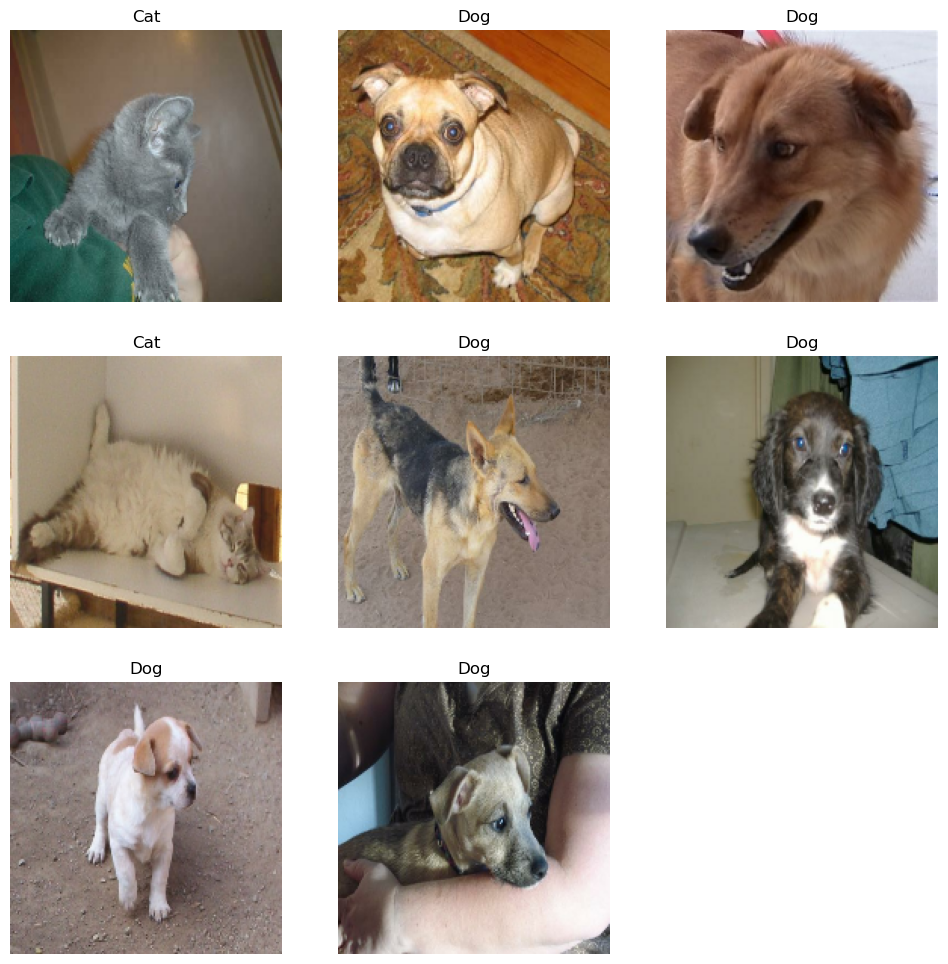

In [9]:
## Print Random Images
import matplotlib.pyplot as plt

# Take one batch from the training dataset
image_batch, label_batch = next(iter(train_dataset))

plt.figure(figsize=(12, 12))

for i in range(8):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].numpy().astype("uint8"))
    plt.title("Cat" if label_batch[i] == 0 else "Dog")
    plt.axis("off")

plt.show()


In [14]:
image_batch, label_batch = next(iter(train_dataset))


## Apply ResNet50 Preprocessing

In [16]:
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.applications.resnet50 import preprocess_input

##preprocessed_batch = preprocess_input(image_batch)


# Apply preprocessing to each batch
train_dataset = train_dataset.map(lambda x, y: (preprocess_input(x), y))
validation_dataset = validation_dataset.map(lambda x, y: (preprocess_input(x), y))


In [12]:
## Optional but Recommended: Prefetching for Speed
train_dataset = train_dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=tf.data.AUTOTUNE)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-351.299..-76.558].


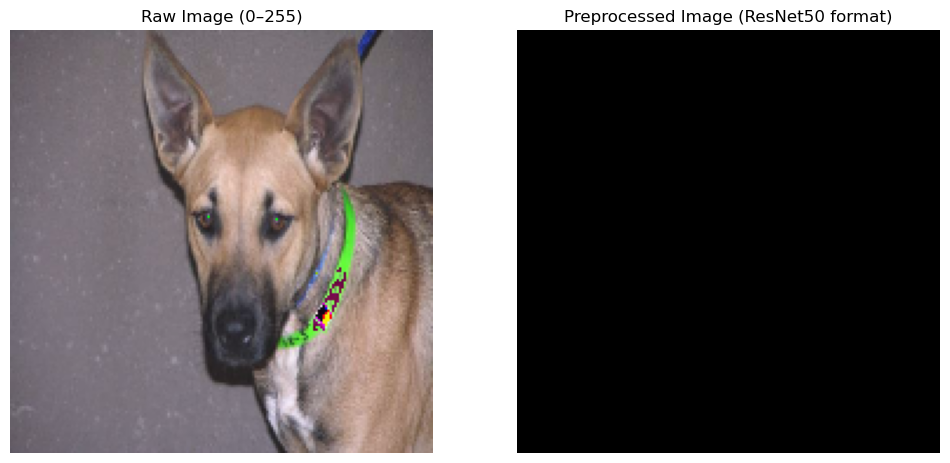

In [18]:
import matplotlib.pyplot as plt
from tensorflow.keras.applications.resnet50 import preprocess_input

# Step 1: Get one batch
image_batch, label_batch = next(iter(train_dataset))

# Pick one image
raw_img = image_batch[0].numpy().astype("uint8")

# Step 2: Preprocess it
preprocessed_img = preprocess_input(image_batch[0])
preprocessed_img_np = preprocessed_img.numpy()

# Step 3: Plot raw vs preprocessed
plt.figure(figsize=(12, 6))

# Raw image
plt.subplot(1, 2, 1)
plt.imshow(raw_img)
plt.title("Raw Image (0–255)")
plt.axis("off")

# Preprocessed image
plt.subplot(1, 2, 2)
plt.imshow(preprocessed_img_np)
plt.title("Preprocessed Image (ResNet50 format)")
plt.axis("off")

plt.show()


## Load ResNet50 and Freeze Base Layers

In [19]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

# Load pretrained ResNet50 without the top classifier
base_model = ResNet50(
    weights="imagenet",
    include_top=False,          # remove the final dense layers
    input_shape=(180, 180, 3)
)

# Freeze all convolutional layers
base_model.trainable = False

# Build the new model on top
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(1, activation="sigmoid")   # binary classification: cat vs dog
])

model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step 


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 6, 6, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           2,049 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

######
We load ResNet50 pretrained on ImageNet — it already knows how to detect edges, textures, and shapes.

We remove the top classification layers because they were trained for 1000 ImageNet classes.

We freeze the convolutional base so those weights don’t change during training.

We add a simple classifier on top — just one dense layer for cats vs dogs.

This setup is called feature extraction — we reuse learned features instead of retraining everything.

## Compile the model

In [21]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


## Train the Model

In [22]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)


Epoch 1/10


C:\Users\phdst\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


621/621 ━━━━━━━━━━━━━━━━━━━━ 438s 687ms/step - accuracy: 0.9487 - loss: 0.1209 - val_accuracy: 0.9631 - val_loss: 0.0925
Epoch 2/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 372s 597ms/step - accuracy: 0.9670 - loss: 0.0822 - val_accuracy: 0.9605 - val_loss: 0.1039
Epoch 3/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 366s 588ms/step - accuracy: 0.9716 - loss: 0.0728 - val_accuracy: 0.9581 - val_loss: 0.1154
Epoch 4/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 30492s 49s/step - accuracy: 0.9733 - loss: 0.0669 - val_accuracy: 0.9654 - val_loss: 0.0899
Epoch 5/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 395s 634ms/step - accuracy: 0.9758 - loss: 0.0619 - val_accuracy: 0.9649 - val_loss: 0.0932
Epoch 6/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 430s 690ms/step - accuracy: 0.9780 - loss: 0.0571 - val_accuracy: 0.9589 - val_loss: 0.1157
Epoch 7/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 432s 695ms/step - accuracy: 0.9787 - loss: 0.0549 - val_accuracy: 0.9607 - val_loss: 0.1095
Epoch 8/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 410s 659ms/step - accuracy: 0.9812 - loss: 0.05

In [23]:
## Plot Training Curves - Accuracy and Loss

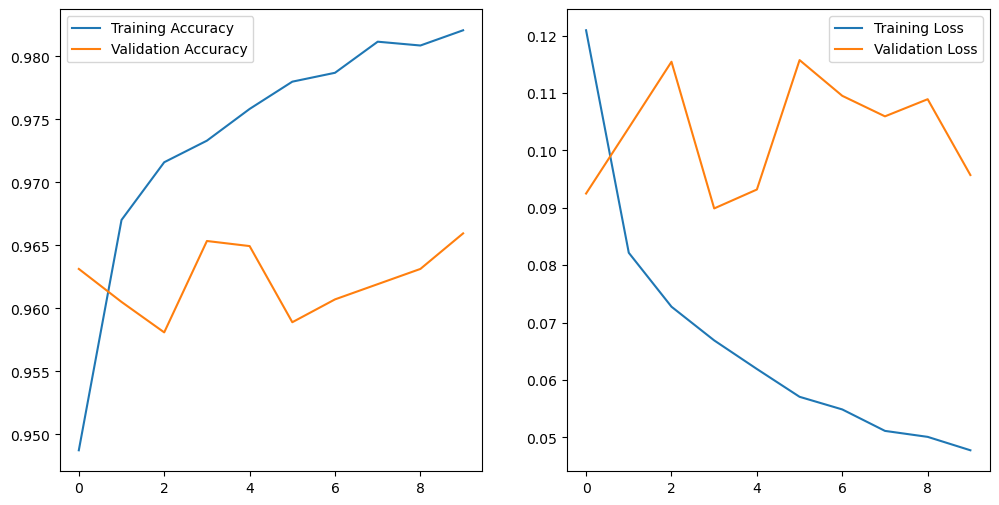

In [24]:
import matplotlib.pyplot as plt

acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(len(acc))

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.legend()

plt.show()


In [35]:
## Predict new data?

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(180, 180),
    batch_size=32,
    shuffle=False
)



Found 24824 files belonging to 2 classes.
Using 4964 files for validation.


In [26]:
# Apply Pre-processing
from tensorflow.keras.applications.resnet50 import preprocess_input
validation_dataset = validation_dataset.map(lambda x, y: (preprocess_input(x), y))


In [27]:
# Predict
pred_probs = model.predict(validation_dataset)
pred_labels = (pred_probs > 0.5).astype("int32")


156/156 ━━━━━━━━━━━━━━━━━━━━ 87s 536ms/step 


In [28]:
# Extract TRUE labels (Actual)
import numpy as np

true_labels = []
for _, labels in validation_dataset:
    true_labels.extend(labels.numpy())

true_labels = np.array(true_labels)


In [29]:
print(true_labels)

[1 1 1 ... 1 1 1]


In [30]:
## Extract Images for Visualization
val_images = []
for images, _ in validation_dataset:
    val_images.extend(images.numpy())


In [31]:
## Print Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score

cm = confusion_matrix(true_labels, pred_labels)
acc = accuracy_score(true_labels, pred_labels)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy:", acc)


Confusion Matrix:
[[   0    0]
 [ 103 4861]]

Accuracy: 0.9792506043513296


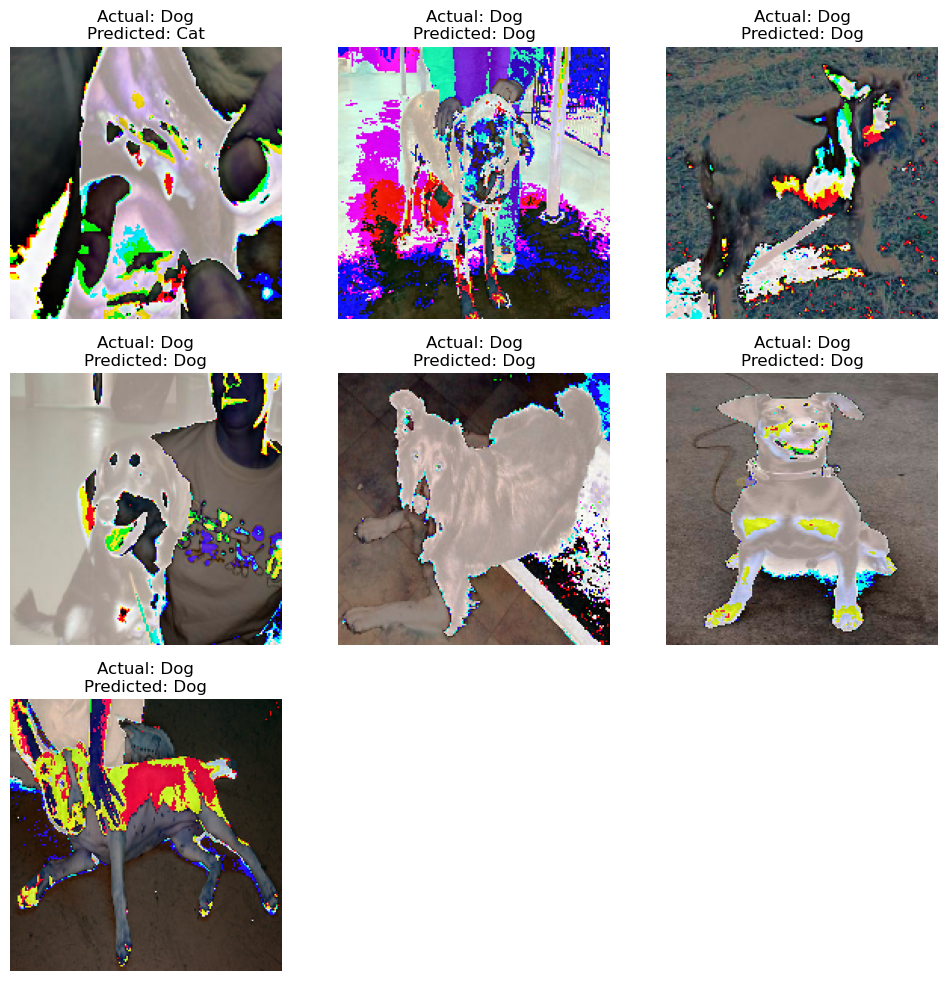

In [44]:
## Print Predicted Images
#import matplotlib.pyplot as plt

class_names = ["Cat", "Dog"]

plt.figure(figsize=(12, 12))

for i in range(7):   # show 7 images
    plt.subplot(3, 3, i+1)
    img = val_images[i].astype("uint8")  # convert back for display

    true_label = class_names[true_labels[i]]
    pred_label = class_names[pred_labels[i][0]]

    plt.imshow(img)
    plt.title(f"Actual: {true_label}\nPredicted: {pred_label}")
    plt.axis("off")

plt.show()


AUC: nan


C:\Users\phdst\anaconda3\Lib\site-packages\sklearn\metrics\_ranking.py:1179: UndefinedMetricWarning: No negative samples in y_true, false positive value should be meaningless
  warnings.warn(


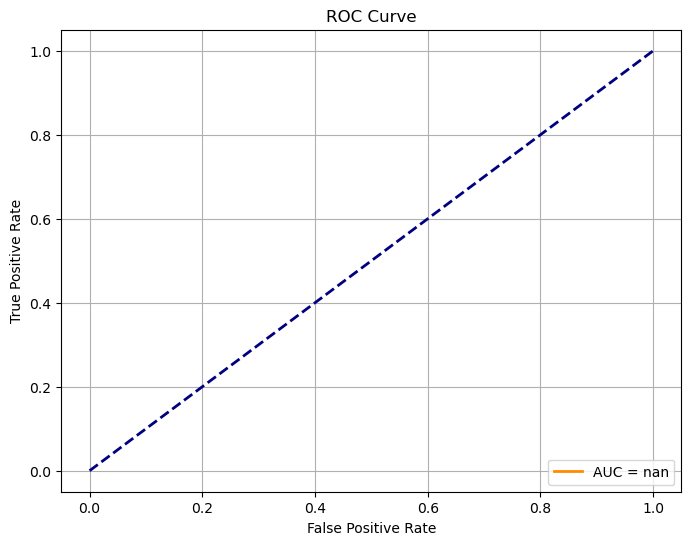

In [45]:
## ROC Curve + AUC
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(true_labels, pred_probs)

# Compute AUC
roc_auc = auc(fpr, tpr)

print("AUC:", roc_auc)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")  # diagonal line
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()
